In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [2]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T

print("Hunting for the mounted YOLO dataset in Kaggle inputs...")
DATA_ROOT = None

for root, dirs, files in os.walk('/kaggle/input'):
    if 'train' in dirs and 'val' in dirs:
        if os.path.exists(os.path.join(root, 'train', 'images')):
            DATA_ROOT = root
            break

if not DATA_ROOT:
    raise ValueError("CRITICAL ERROR: Could not find the dataset. Please ensure it is attached.")

print(f"Success! Found raw dataset at: {DATA_ROOT}")

TRAIN_IMG_DIR = os.path.join(DATA_ROOT, 'train/images')
TRAIN_LBL_DIR = os.path.join(DATA_ROOT, 'train/labels')
VAL_IMG_DIR = os.path.join(DATA_ROOT, 'val/images')
VAL_LBL_DIR = os.path.join(DATA_ROOT, 'val/labels')

class TFBFasterRCNNDataset(Dataset):
    def __init__(self, img_dir, label_dir, transforms=None):
        self.img_dir = img_dir
        self.label_dir = label_dir
        self.transforms = transforms
        self.imgs = sorted([f for f in os.listdir(img_dir) if f.endswith(('.jpg', '.png'))])

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img_name = self.imgs[idx]
        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert("RGB")
        w, h = image.size
        
        label_name = img_name.rsplit('.', 1)[0] + '.txt'
        label_path = os.path.join(self.label_dir, label_name)
        
        boxes = []
        labels = []
        
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) != 5: continue
                        
                    class_id, cx, cy, bw, bh = map(float, parts)
                    xmin = max(0, (cx - bw / 2) * w)
                    xmax = min(w, (cx + bw / 2) * w)
                    ymin = max(0, (cy - bh / 2) * h)
                    ymax = min(h, (cy + bh / 2) * h)
                    
                    if xmax <= xmin or ymax <= ymin: continue
                    boxes.append([xmin, ymin, xmax, ymax])
                    labels.append(int(class_id) + 1)
        
        boxes = torch.as_tensor(boxes, dtype=torch.float32) if len(boxes) > 0 else torch.zeros((0, 4), dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)
        
        target = {"boxes": boxes, "labels": labels, "image_id": torch.tensor([idx])}
        if self.transforms:
            image = self.transforms(image)

        return image, target

def collate_fn(batch):
    return tuple(zip(*batch))

transform = T.Compose([T.ToTensor()])

# Setup Loaders
train_dataset = TFBFasterRCNNDataset(TRAIN_IMG_DIR, TRAIN_LBL_DIR, transforms=transform)
val_dataset = TFBFasterRCNNDataset(VAL_IMG_DIR, VAL_LBL_DIR, transforms=transform)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=4, pin_memory=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=4, pin_memory=True, collate_fn=collate_fn)

print(f"Loaded {len(train_dataset)} Training Images and {len(val_dataset)} Validation Images.")

Hunting for the mounted YOLO dataset in Kaggle inputs...
Success! Found raw dataset at: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset
Loaded 16574 Training Images and 4736 Validation Images.


In [3]:
import os

print("Top-level folders in Kaggle input:")
for item in os.listdir('/kaggle/input'):
    print(f"- {item}")

Top-level folders in Kaggle input:
- datasets
- notebooks


In [4]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from tqdm import tqdm
import os

# 1. Model Setup
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(f"Training on device: {device}")

NUM_CLASSES = 10  
weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn_v2(weights=weights)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
model.to(device)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

# 2. Bulletproof Disguise Auto-Resume
NUM_EPOCHS = 10
WEIGHTS_PATH = None

print("Hunting for the disguised 'latest_phase2.txt' weights...")
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if 'latest_phase2' in file and file.endswith('.txt'):
            WEIGHTS_PATH = os.path.join(root, file)
            break 
    if WEIGHTS_PATH: break

if WEIGHTS_PATH:
    print(f"Success! Found intact checkpoint at: {WEIGHTS_PATH}")
    checkpoint = torch.load(WEIGHTS_PATH, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    lr_scheduler.load_state_dict(checkpoint['lr_scheduler_state_dict'])
    START_EPOCH = checkpoint['epoch']
    print(f"Restored state. Running the final lap: Epoch {START_EPOCH + 1}...")
else:
    raise FileNotFoundError("CRITICAL ERROR: Could not find 'faster_rcnn_latest_phase2.txt'. Ensure it is attached.")

# 3. Training Loop (Epoch 10)
for epoch in range(START_EPOCH, NUM_EPOCHS):
    model.train() 
    epoch_loss = 0
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}")
    
    for images, targets in progress_bar:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()
        
        epoch_loss += losses.item()
        progress_bar.set_postfix(loss=losses.item())
        
    lr_scheduler.step()
    print(f"Epoch {epoch+1} Completed | Average Loss: {epoch_loss / len(train_loader):.4f}")

    if (epoch + 1) == NUM_EPOCHS:
        save_path = f'/kaggle/working/faster_rcnn_epoch_{NUM_EPOCHS}_FINAL.pth'
        checkpoint_data = {
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'lr_scheduler_state_dict': lr_scheduler.state_dict()
        }
        torch.save(checkpoint_data, save_path)
        print(f"\n[INFO] Mission Accomplished! The ultimate model is safely stored at: {save_path}")

Training on device: cuda
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 212MB/s]


Hunting for the disguised 'latest_phase2.txt' weights...
Success! Found intact checkpoint at: /kaggle/input/datasets/sharminaktermukta/9th-epoch/faster_rcnn_latest_phase2.txt
Restored state. Running the final lap: Epoch 10...


Epoch 10/10: 100%|██████████| 2072/2072 [2:00:38<00:00,  3.49s/it, loss=0.288]


Epoch 10 Completed | Average Loss: 0.3274

[INFO] Mission Accomplished! The ultimate model is safely stored at: /kaggle/working/faster_rcnn_epoch_10_FINAL.pth


Beginning Evaluation on Validation Set to calculate mAP50 and mAP50-95...


Evaluating: 100%|██████████| 592/592 [14:12<00:00,  1.44s/it]



Computing metrics (this may take a minute)...

**************************************************************************
FINAL CONSOLIDATED EVALUATION RESULTS
**************************************************************************
Condition              | mAP50             | mAP50-95
--------------------------------------------------------------------------
Clean Baseline         | 0.7191            | 0.4678
**************************************************************************

Generating Bounding Box Visualizations...


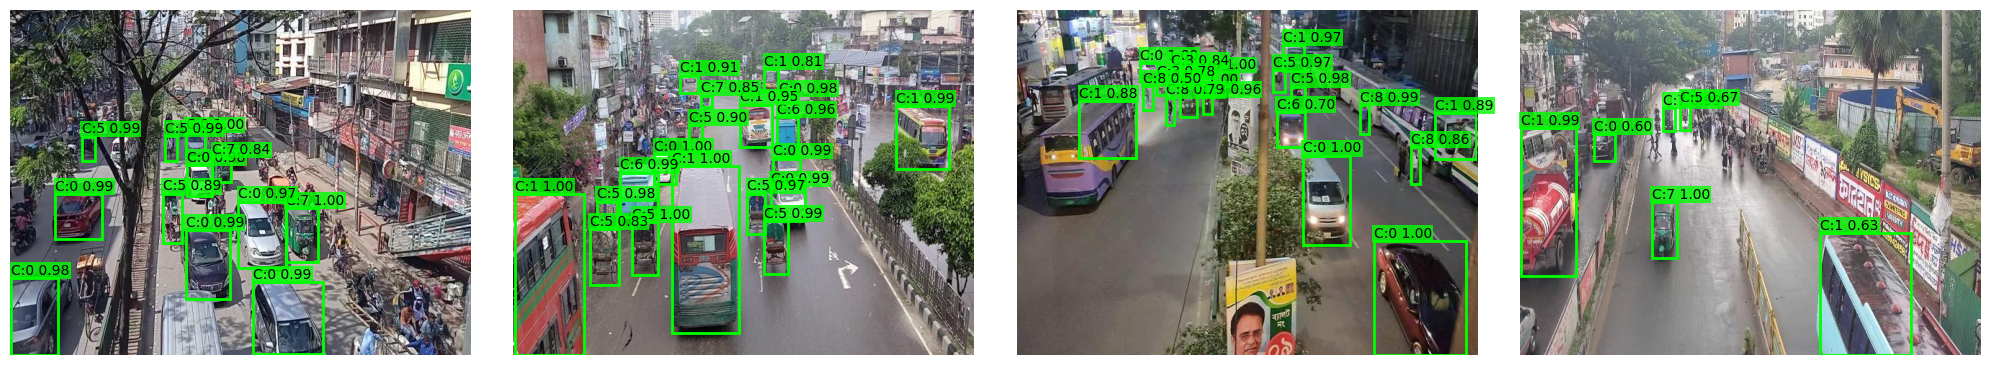

In [5]:
!pip install torchmetrics -q

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from torchmetrics.detection.mean_ap import MeanAveragePrecision

print("Beginning Evaluation on Validation Set to calculate mAP50 and mAP50-95...")
metric = MeanAveragePrecision(iou_type="bbox")
model.eval() 

with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Evaluating"):
        images_gpu = list(img.to(device) for img in images)
        outputs = model(images_gpu)
        
        preds = [{'boxes': out['boxes'].cpu(), 'scores': out['scores'].cpu(), 'labels': out['labels'].cpu()} for out in outputs]
        targs = [{'boxes': t['boxes'].cpu(), 'labels': t['labels'].cpu()} for t in targets]
        metric.update(preds, targs)

print("\nComputing metrics (this may take a minute)...")
results = metric.compute()
map50 = results['map_50'].item()
map50_95 = results['map'].item()

# Console Output exactly matching the requested structure
print("\n" + "*" * 74)
print("FINAL CONSOLIDATED EVALUATION RESULTS")
print("*" * 74)
print(f"{'Condition':<22} | {'mAP50':<17} | {'mAP50-95'}")
print("-" * 74)
print(f"{'Clean Baseline':<22} | {map50:<17.4f} | {map50_95:.4f}")
print("*" * 74 + "\n")

def visualize_predictions(data_loader, eval_model, num_images=4):
    images, targets = next(iter(data_loader))
    images_gpu = list(img.to(device) for img in images)
    
    with torch.no_grad():
        outputs = eval_model(images_gpu)
        
    fig, axes = plt.subplots(1, num_images, figsize=(20, 5))
    
    for i in range(min(num_images, len(images))):
        img = images[i].permute(1, 2, 0).numpy()
        out = outputs[i]
        
        boxes = out['boxes'].cpu().numpy()
        scores = out['scores'].cpu().numpy()
        labels = out['labels'].cpu().numpy()
        
        ax = axes[i]
        ax.imshow(img)
        ax.axis('off')
        
        for box, score, label in zip(boxes, scores, labels):
            if score >= 0.50:
                xmin, ymin, xmax, ymax = box
                rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, linewidth=2, edgecolor='#00FF00', facecolor='none')
                ax.add_patch(rect)
                ax.text(xmin, ymin - 5, f'C:{label-1} {score:.2f}', color='black', fontsize=10, bbox=dict(facecolor='#00FF00', alpha=0.8, edgecolor='none', pad=1))
    
    plt.tight_layout()
    plt.show()

print("Generating Bounding Box Visualizations...")
visualize_predictions(val_loader, model)